# Interior-point method

In [34]:
import contextlib
import io

import casadi as ca
import numpy as np
import matplotlib.pyplot as plt

from solvers.interior_point import interior_point
from solvers.newton_damped import newton_damped
from solvers.sqp import sqp

# Results storage for summary
optimization_results = []


# Helper function to record results
def record_result(example_name, x_g, l_g, post_proc, x_initial, m_g=None):
    """Record optimization result for summary"""
    result = {
        "example": example_name,
        "initial_guess": x_initial.flatten(),
        "iterations": len(post_proc["step"]),
        "solution": x_g.flatten(),
        "kkt_violation": post_proc["kkt_violation"][-1],
    }
    result["equality_multiplier"] = l_g.flatten()
    if m_g is not None:
        result["inequality_multiplier"] = m_g.flatten()
    optimization_results.append(result)


def fmt(v, digits=4):
    """Format a vector with the given number of significant digits"""
    return "[" + ", ".join(f"{e:.{digits}g}" for e in v) + "]"

## Interior-point solver

The solver is implemented in `solvers/interior_point.py`. It re-uses the structure of the SQP solver; the main changes are:

- **Newton direction**: instead of solving a QP, solve the IP linear system $\nabla r_\tau^\top z = -r_\tau$ in **full form**, with
  $$r_\tau(x, \lambda, \mu, s) = \begin{bmatrix} \nabla_x L \\ g \\ h + s \\ \operatorname{diag}(\mu)\, s - \mathbf{1}\tau \end{bmatrix}$$
  and $z = (\Delta x, \Delta\lambda, \Delta\mu, \Delta s)$ (increments).
- **Fraction to the boundary** ($\varepsilon = 0.01$): largest $\bar\alpha \le 1$ such that $s + \bar\alpha \Delta s \ge \varepsilon s$ and $\mu + \bar\alpha \Delta\mu \ge \varepsilon \mu$, so that $s, \mu$ stay positive.
- **Line search** on the merit function $M_1(x, s) = f(x) - \tau \sum_i \log(s_i) + \sigma \|g(x)\|_1 + \sigma \|h(x) + s\|_1$, starting from $\bar\alpha$.
- **Barrier update**: whenever $\|r_\tau\|_\infty \le \tau$, $\tau \leftarrow \max(0.1\tau, \text{tol})$.
- **Initialization**: $\mu = 1$ (default) and $s = \tau / \mu$, so that $\mu_i s_i = \tau$.

The solver stops when the KKT violation $\|(\nabla_x L, g, \max(0, h))\|_\infty$ is below tol **and** $\tau$ has reached tol.

## Plot function

In [35]:
def plot_ip(post_proc, f, g, h, x_g):
    fig = plt.figure(figsize=(12, 10))

    # Contour plot in the (x1, x2) plane: only for problems with 2 variables
    n_h = h.size1_out(0)  # number of inequality constraints
    if x_g.shape[0] == 2:
        x1 = np.linspace(-2, 2, 100)
        x2 = np.linspace(-2, 2, 100)
        X1, X2 = np.meshgrid(x1, x2)
        F = np.zeros_like(X1)
        G = np.zeros_like(X1)
        H = np.zeros_like(X1)
        for i in range(X1.shape[0]):
            for j in range(X1.shape[1]):
                x_val = np.array([[X1[i, j]], [X2[i, j]]])
                F[i, j] = float(f(x_val))
                G[i, j] = float(g(x_val))
                if n_h > 0:
                    H[i, j] = float(h(x_val))

        ax = fig.add_subplot(221)
        ax.contour(X1, X2, F, levels=20, cmap="viridis")
        ax.contour(X1, X2, G, levels=[0], colors="red", linewidths=2)
        if n_h > 0:
            ax.contour(X1, X2, H, levels=[0], colors="blue", linewidths=2)
            ax.contourf(X1, X2, H, levels=[-np.inf, 0], colors="blue", alpha=0.2)  # h(x) <= 0
        x_hist = np.array(post_proc["x"])
        ax.plot(x_hist[:, 0], x_hist[:, 1], "k-o", label="Iterations", markersize=4)
        ax.plot(x_g[0], x_g[1], "ro", label="Solution", markersize=8)
        ax.set_title("Iterates (red: g(x) = 0, blue: h(x) <= 0)")
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
        ax.legend()
        ax.set_xlim(x1[0], x1[-1])  # same limits in all the figures
        ax.set_ylim(x2[0], x2[-1])
        ax.set_aspect("equal", adjustable="box")
        ax.grid()

    # More than 2 variables: plot each component of x over the iterations
    else:
        ax = fig.add_subplot(221)
        x_hist = np.array(post_proc["x"])
        for i in range(x_hist.shape[1]):
            ax.plot(x_hist[:, i], "-o", markersize=4, label=f"x{i + 1}")
        ax.set_title("Iterates over Iterations")
        ax.set_xlabel("Iteration")
        ax.legend()
        ax.grid()

    # KKT violation
    ax = fig.add_subplot(222)
    ax.semilogy(post_proc["kkt_violation"], "b-o", markersize=4)
    ax.set_title("KKT Violation over Iterations")
    ax.set_xlabel("Iteration")
    ax.grid()

    # Step size
    ax = fig.add_subplot(223)
    ax.plot(post_proc["step"], post_proc["alpha"], "m-o", markersize=4)
    ax.set_title("Step Size (alpha) over Iterations")
    ax.set_xlabel("Iteration")
    ax.grid()

    # Barrier parameter
    ax = fig.add_subplot(224)
    ax.semilogy(post_proc["step"], post_proc["tau"], "g-o", markersize=4)
    ax.set_title("Barrier Parameter (tau) over Iterations")
    ax.set_xlabel("Iteration")
    ax.grid()

    plt.tight_layout()
    return fig

## Tests

### Strictly convex QP

Same QP used to test the SQP solver (SQP notebook), with the inequality active at the solution.


      tau |  Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
  1.0e+00 |     1 |     1.760000 |    2.220e-16 |       4.441e-16 |   1.000000 |       [-2.0000e-01, 1.2000e+00] |       [-3.4000e+00]
  1.0e-01 |     2 |     1.507219 |    0.000e+00 |       4.441e-16 |   1.000000 |       [-7.1429e-03, 1.0071e+00] |       [-3.0143e+00]
  1.0e-01 |     3 |     1.444764 |    0.000e+00 |       4.441e-16 |   1.000000 |        [6.0776e-02, 9.3922e-01] |       [-2.8784e+00]
  1.0e-02 |     4 |     1.386632 |    0.000e+00 |       3.886e-16 |   1.000000 |        [1.4483e-01, 8.5517e-01] |       [-2.7103e+00]
  1.0e-02 |     5 |     1.371495 |    0.000e+00 |       5.551e-17 |   1.000000 |        [1.7383e-01, 8.2617e-01] |       [-2.6523e+00]
  1.0e-03 |     6 |     1.362239 |   -1.110e-16 |       1.110e-16 |   1.000000 |        [1.9452e-01, 8.0548e-01] |       [-2.6110e+00]
  1.0e-03 |     7 |     1.361017 |    0.000e+00 |     

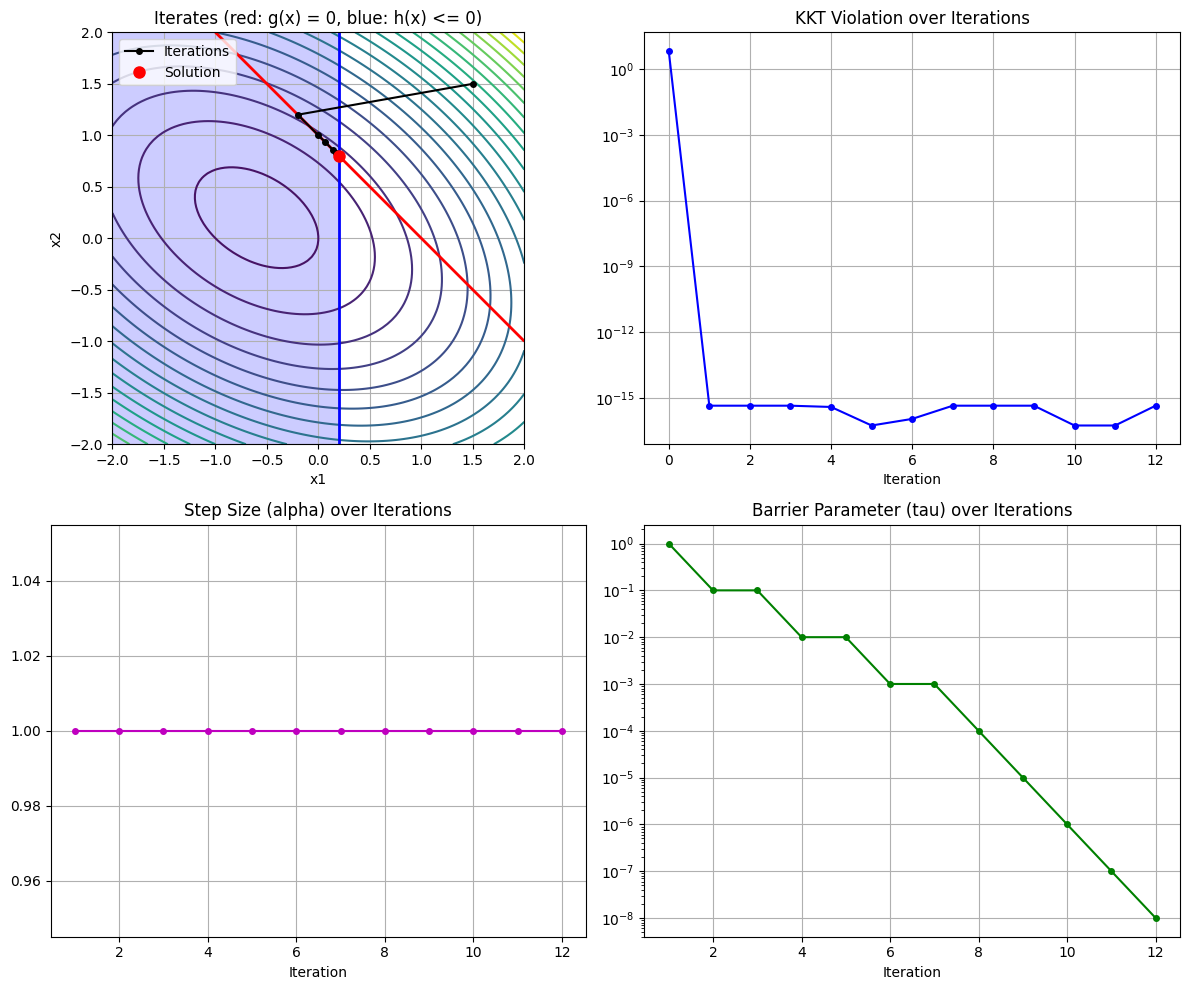

In [36]:
x = ca.SX.sym("x", 2)
Q = np.array([[2.0, 1.0], [1.0, 3.0]])
f_qp = ca.Function("f", [x], [0.5 * x.T @ Q @ x + x[0]])
g_qp = ca.Function("g", [x], [x[0] + x[1] - 1])
h_qp = ca.Function("h", [x], [x[0] - 0.2])

x_qp, l_qp, m_qp, s_qp, post_proc = interior_point(
    f_qp, g_qp, h_qp, np.array([[1.5], [1.5]]), np.array([[0.0]]), tol=1e-8
)
fig = plot_ip(post_proc, f_qp, g_qp, h_qp, x_qp)

**Observations.** The solver reaches the solution $x = (0.2, 0.8)$ taking only full steps ($\alpha = 1$), but in 12 iterations, not in one step as SQP. The interior-point method does not solve the QP directly: it solves a sequence of barrier problems while $\tau$ is decreased by a factor 10 from $1$ to $10^{-8}$, i.e. at least 8 updates. For a QP each barrier problem is solved very quickly, so the number of iterations is driven by the decrease of $\tau$.

### Example 1 (Newton notebook)

$$\min_x \; x^\top x + \mathbf{1}^\top x \quad \text{s.t.} \quad x^\top x = 1$$

There are no inequality constraints: we pass an `h` with zero outputs, `ca.Function("h", [x], [ca.SX(0, 1)])`. With $n_h = 0$ there are no slacks and no barrier, so the IP Newton system coincides with the KKT system of Newton's method: the IP solver must reproduce the results of Newton's method.

In [37]:
x = ca.SX.sym("x", 2)
f = ca.Function("f", [x], [x.T @ x + ca.SX.ones(2).T @ x])
g = ca.Function("g", [x], [x.T @ x - 1])
h_none = ca.Function("h", [x], [ca.SX(0, 1)])  # no inequality constraints

results_eq = []


def compare_newton(example, f, g, h, x0, l0, tol=1e-8):
    """Solve with the interior-point method (and plot), then with Newton's method for comparison"""
    row = {"x0": x0.flatten()}
    try:
        x_ip, l_ip, m_ip, _, post_proc = interior_point(f, g, h, x0, l0, tol=tol)
        record_result(example, x_ip, l_ip, post_proc, x0, m_ip)
        plot_ip(post_proc, f, g, h, x_ip)
        row["ip_x"], row["ip_iter"] = x_ip.flatten(), len(post_proc["step"])
    except Exception as e:
        print("Interior point failed:", e)
        row["ip_x"], row["ip_iter"] = None, None

    try:
        x_n, _, post_proc_n = newton_damped(f, g, x0, l0, tol=tol)
        row["newton_x"], row["newton_iter"] = x_n.flatten(), len(post_proc_n["step"])
    except Exception as e:
        print("Newton failed:", e)
        row["newton_x"], row["newton_iter"] = None, None

    results_eq.append(row)

#### Initial guesses $(0, 1)$, $(-1, -1)$, $(-1, 1)$


      tau |  Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
  1.0e+00 |     1 |     1.812500 |    6.250e-02 |       1.500e+00 |   0.500000 |       [-2.5000e-01, 1.0000e+00] |       [-7.5000e-01]
  1.0e+00 |     2 |     1.526209 |    1.466e-01 |       1.324e+00 |   0.125000 |       [-5.4320e-01, 9.2279e-01] |       [-8.2445e-01]
  1.0e+00 |     3 |     1.075194 |    3.659e-01 |       1.179e+00 |   0.125000 |       [-9.5890e-01, 6.6816e-01] |       [-8.6568e-01]
  1.0e+00 |     4 |     0.708848 |    4.481e-01 |       1.106e+00 |   0.062500 |       [-1.1360e+00, 3.9683e-01] |       [-8.6630e-01]
  1.0e+00 |     5 |     0.397511 |    5.088e-01 |       1.032e+00 |   0.062500 |       [-1.2232e+00, 1.1191e-01] |       [-8.5741e-01]
  1.0e+00 |     6 |     0.067131 |    6.729e-01 |       8.732e-01 |   0.125000 |      [-1.2409e+00, -3.6490e-01] |       [-8.2619e-01]
  1.0e-01 |     7 |    -0.081182 |    6.492e-01 |     

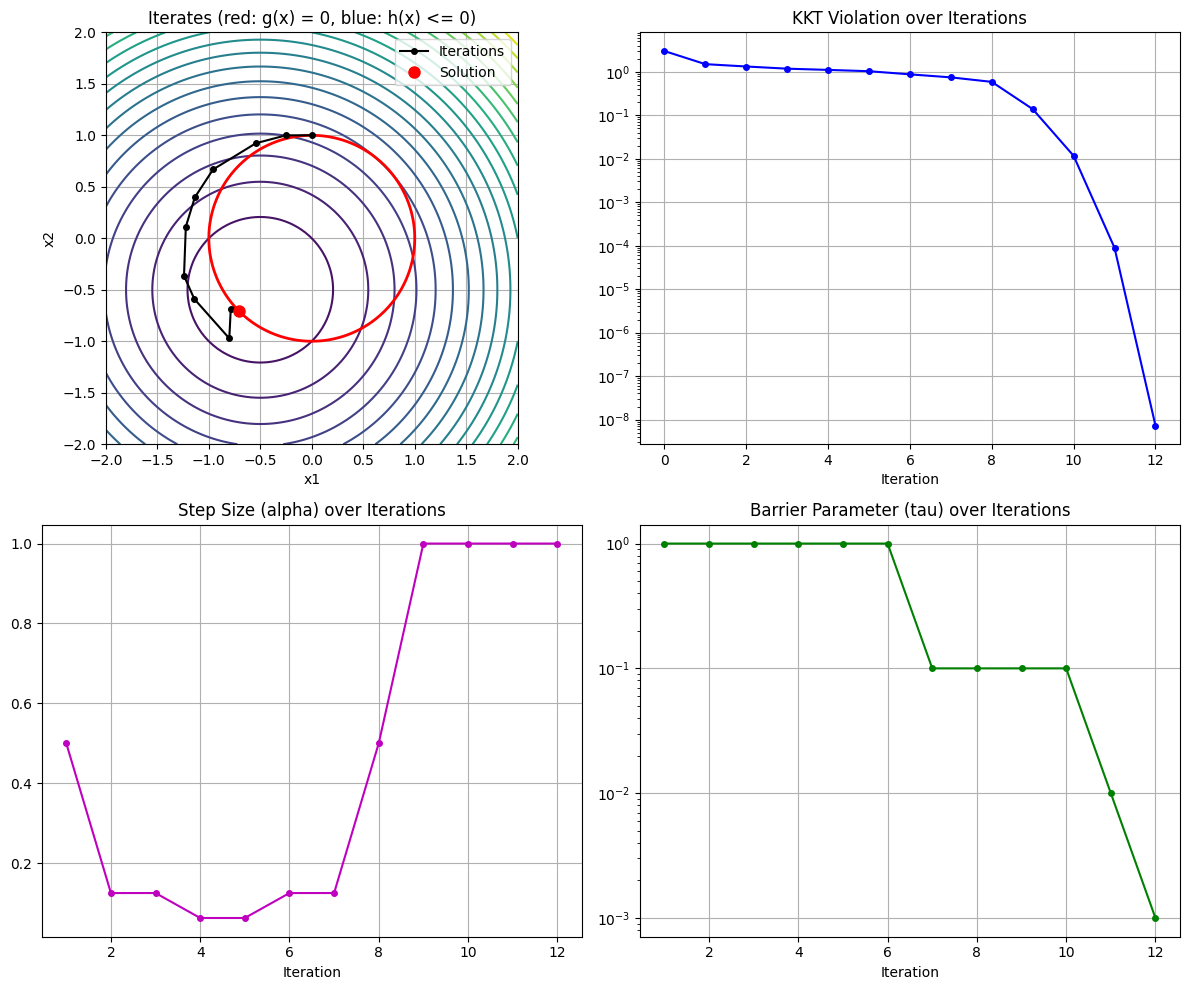

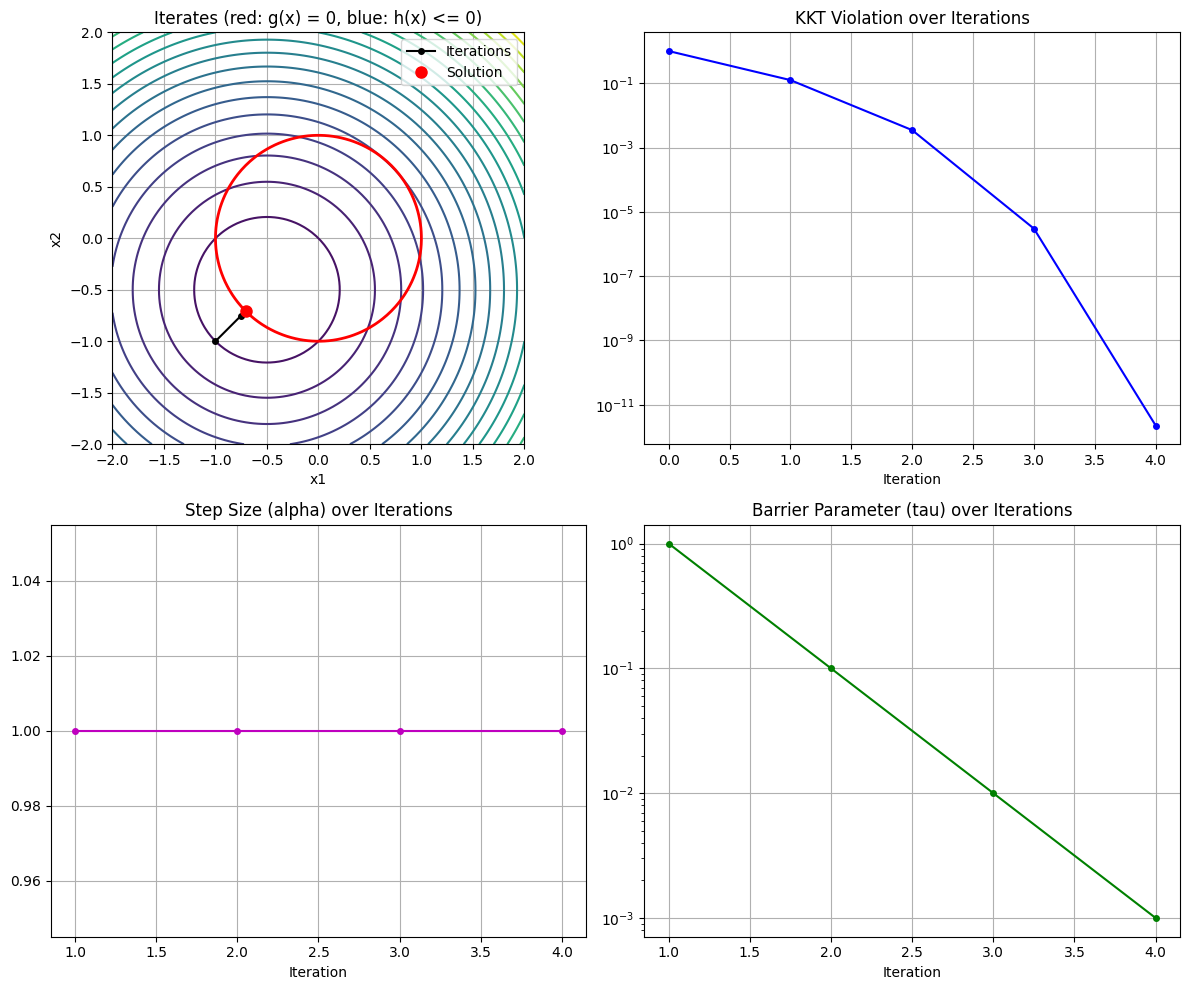

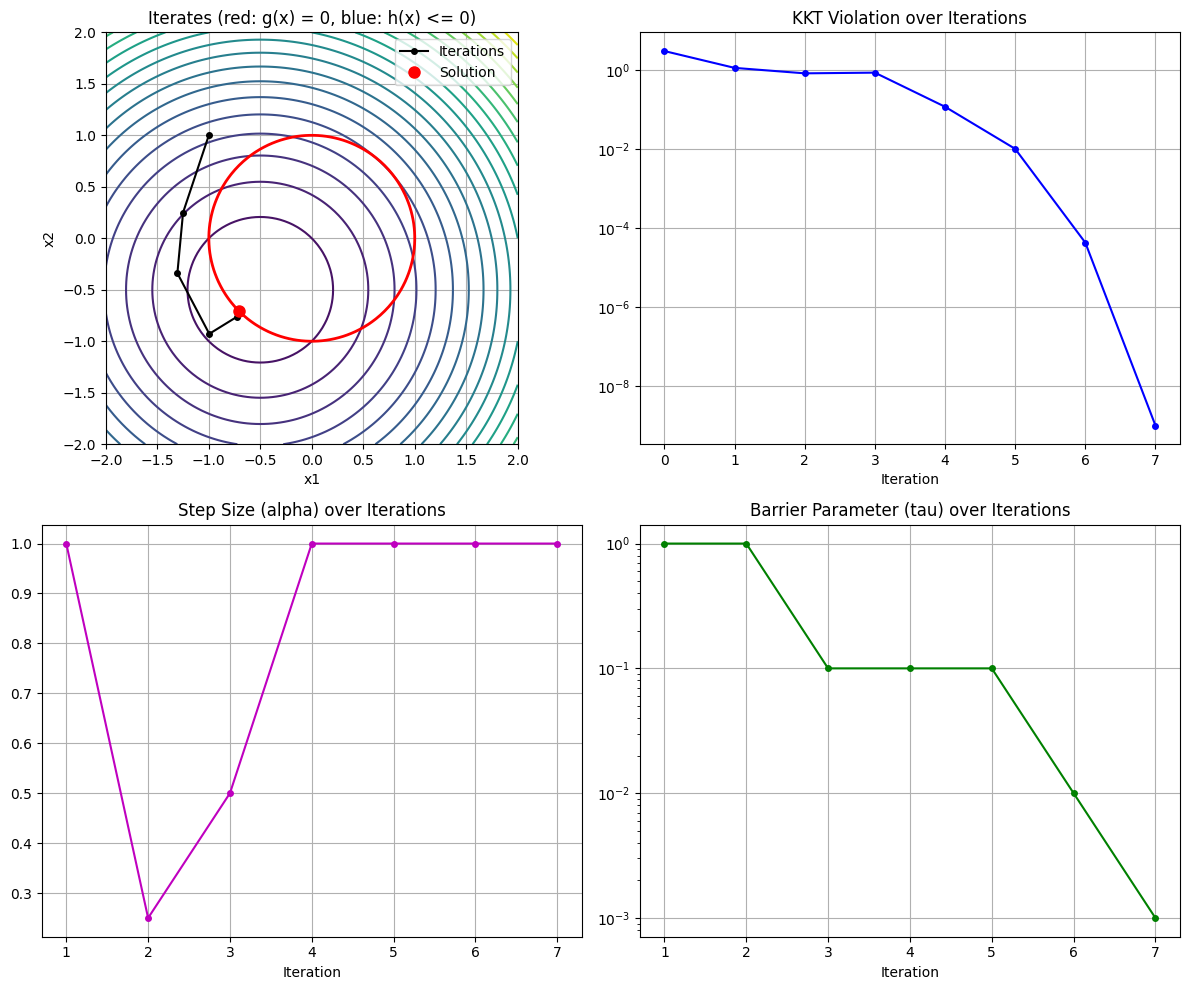

In [38]:
l0 = np.array([[0.0]])
compare_newton("Example 1", f, g, h_none, np.array([[0.0], [1.0]]), l0)
compare_newton("Example 1", f, g, h_none, np.array([[-1.0], [-1.0]]), l0)
compare_newton("Example 1", f, g, h_none, np.array([[-1.0], [1.0]]), l0)

#### Initial guesses $(1, 1)$ and $(1, 1 + 10^{-6})$


      tau |  Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
  1.0e+00 |     1 |     2.625000 |    1.250e-01 |       6.250e-01 |   1.000000 |        [7.5000e-01, 7.5000e-01] |       [-1.2500e+00]
  1.0e-01 |     2 |     2.420139 |    3.472e-03 |       3.588e-02 |   1.000000 |        [7.0833e-01, 7.0833e-01] |       [-1.6806e+00]
  1.0e-02 |     3 |     2.414219 |    3.004e-06 |       6.496e-05 |   1.000000 |        [7.0711e-01, 7.0711e-01] |       [-1.7071e+00]
  1.0e-03 |     4 |     2.414214 |    2.256e-12 |       9.982e-11 |   1.000000 |        [7.0711e-01, 7.0711e-01] |       [-1.7071e+00]
Converged after 4 iterations with KKT violation = 9.982e-11


 Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
    1 |     2.625000 |    1.250e-01 |       6.250e-01 |   1.000000 |        [7.5000e-01, 7.5000e-01] |       [-1.2500e+00]
    2 |     2.42

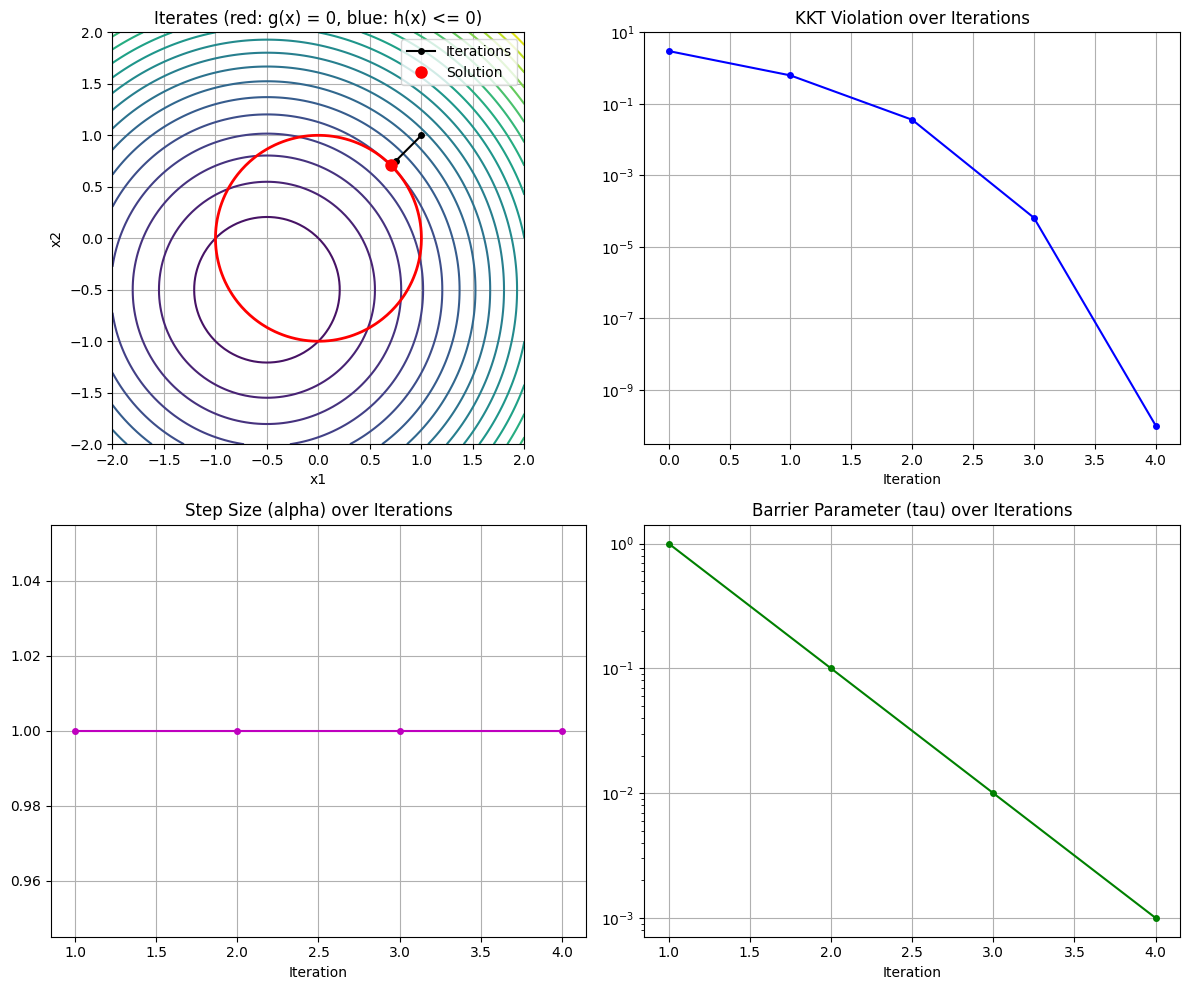

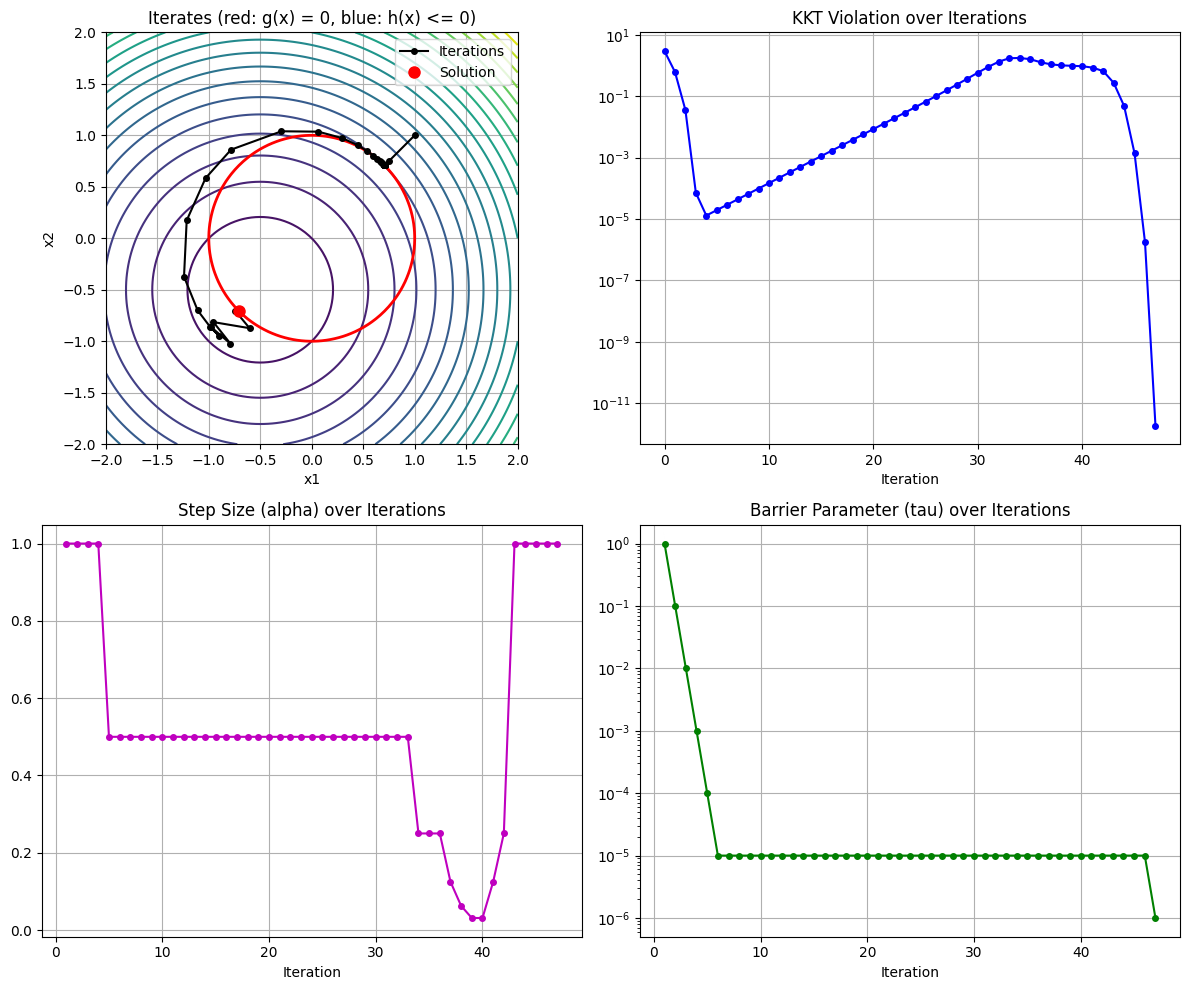

In [39]:
compare_newton("Example 1", f, g, h_none, np.array([[1.0], [1.0]]), l0)
compare_newton("Example 1", f, g, h_none, np.array([[1.0], [1.0 + 1e-6]]), l0)

#### Initial guess $(0, 0)$

In [40]:
compare_newton("Example 1", f, g, h_none, np.array([[0.0], [0.0]]), l0)


      tau |  Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
Interior point failed: KKT matrix is singular at x = [0. 0.]: is LICQ satisfied?

 Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
Newton failed: KKT matrix is singular at x = [0. 0.]: is LICQ satisfied?


#### Initial guess $(0.5, 1)$


      tau |  Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
  1.0e+00 |     1 |     2.312500 |    6.250e-02 |       7.500e-01 |   1.000000 |        [2.5000e-01, 1.0000e+00] |       [-1.5000e+00]
  1.0e-01 |     2 |     2.188477 |    8.002e-02 |       9.246e-01 |   0.250000 |        [7.1691e-02, 1.0368e+00] |       [-1.5257e+00]
  1.0e-01 |     3 |     2.002011 |    1.089e-01 |       1.157e+00 |   0.250000 |       [-1.4924e-01, 1.0424e+00] |       [-1.5275e+00]
  1.0e-01 |     4 |     1.732444 |    1.537e-01 |       1.415e+00 |   0.250000 |       [-4.1288e-01, 9.9159e-01] |       [-1.5028e+00]
  1.0e-01 |     5 |     1.365294 |    2.213e-01 |       1.633e+00 |   0.250000 |       [-7.0613e-01, 8.5011e-01] |       [-1.4481e+00]
  1.0e-01 |     6 |     0.908489 |    3.209e-01 |       1.716e+00 |   0.250000 |       [-9.9229e-01, 5.7988e-01] |       [-1.3610e+00]
  1.0e-01 |     7 |     0.418421 |    4.663e-01 |     

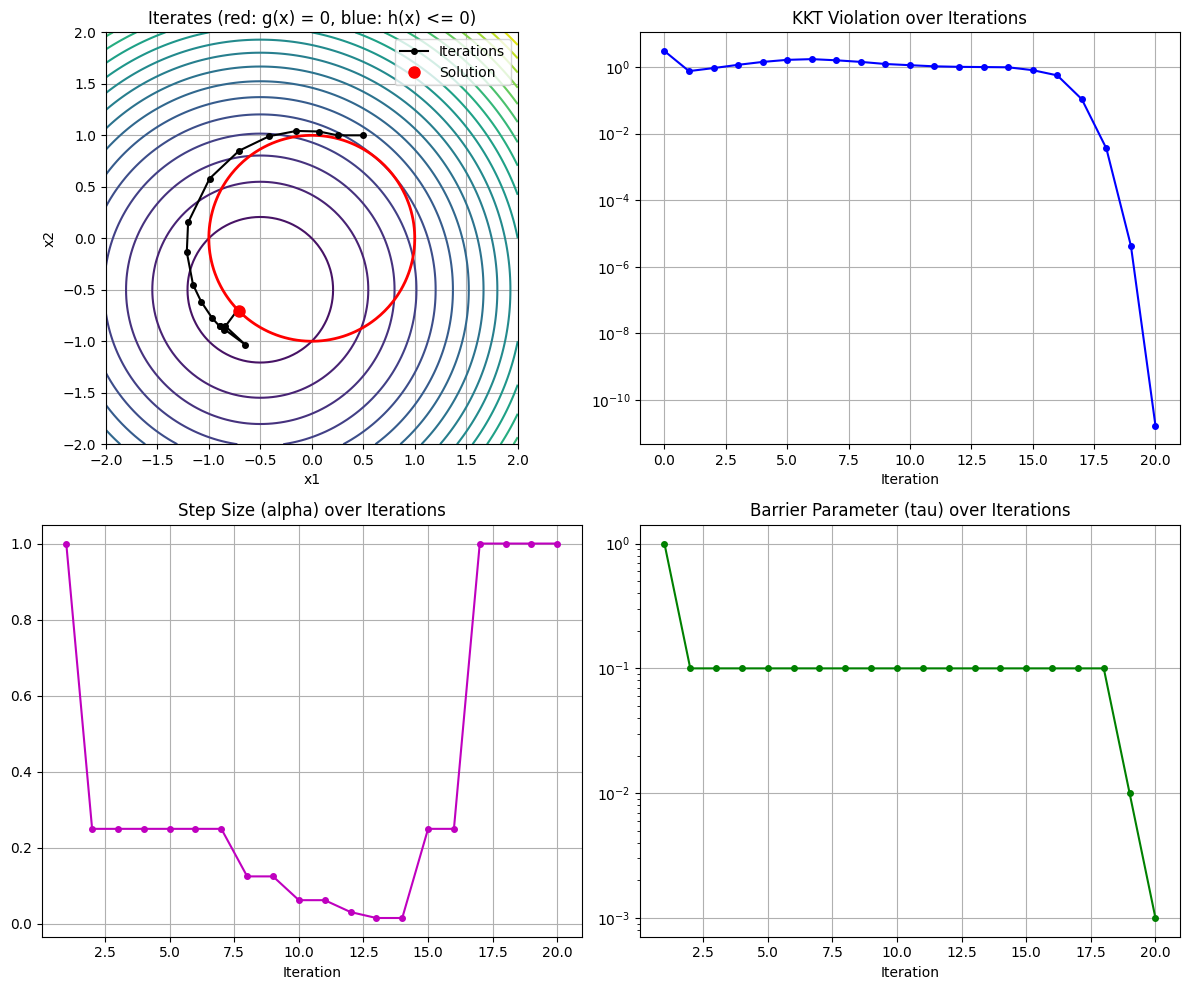

In [41]:
compare_newton("Example 1", f, g, h_none, np.array([[0.5], [1.0]]), l0)

### Example 2 (Newton notebook)

$$\min_{x \in \mathbb{R}^3} \; x^\top x + x_2 \quad \text{s.t.} \quad \begin{bmatrix} x_1^2 - 2x_2^3 - x_2 - 10x_3 \\ x_2 + 10x_3 \end{bmatrix} = 0$$


      tau |  Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
  1.0e+00 |     1 |     0.651598 |   -3.690e-02 |       1.519e+00 |   1.000000 | [-3.0120e-01, 3.9960e-01, -3... | [3.0120e-01, 3.0...
  1.0e+00 |     2 |     0.073409 |    9.504e-02 |       1.623e+00 |   1.000000 | [3.0825e-01, -2.2104e-02, 2.... | [1.6329e+00, 1.6...
  1.0e+00 |     3 |    -0.217238 |    1.622e-01 |       4.057e-01 |   1.000000 | [1.5224e-01, -4.1115e-01, 4.... | [3.3253e-01, 3.2...
  1.0e-01 |     4 |    -0.210216 |    5.709e-02 |       7.786e-02 |   1.000000 | [-2.5083e-02, -3.0448e-01, 3... | [5.5208e-01, 5.4...
  1.0e-02 |     5 |    -0.162579 |    1.752e-02 |       2.280e-01 |   1.000000 | [1.3887e-02, -2.0537e-01, 2.... | [1.4114e+00, 1.4...
  1.0e-02 |     6 |    -0.142292 |    1.022e-02 |       1.925e-01 |   0.500000 | [2.0671e-04, -1.7226e-01, 1.... | [2.5811e+00, 2.5...
  1.0e-02 |     7 |    -0.101522 |    3.029e-03 |     

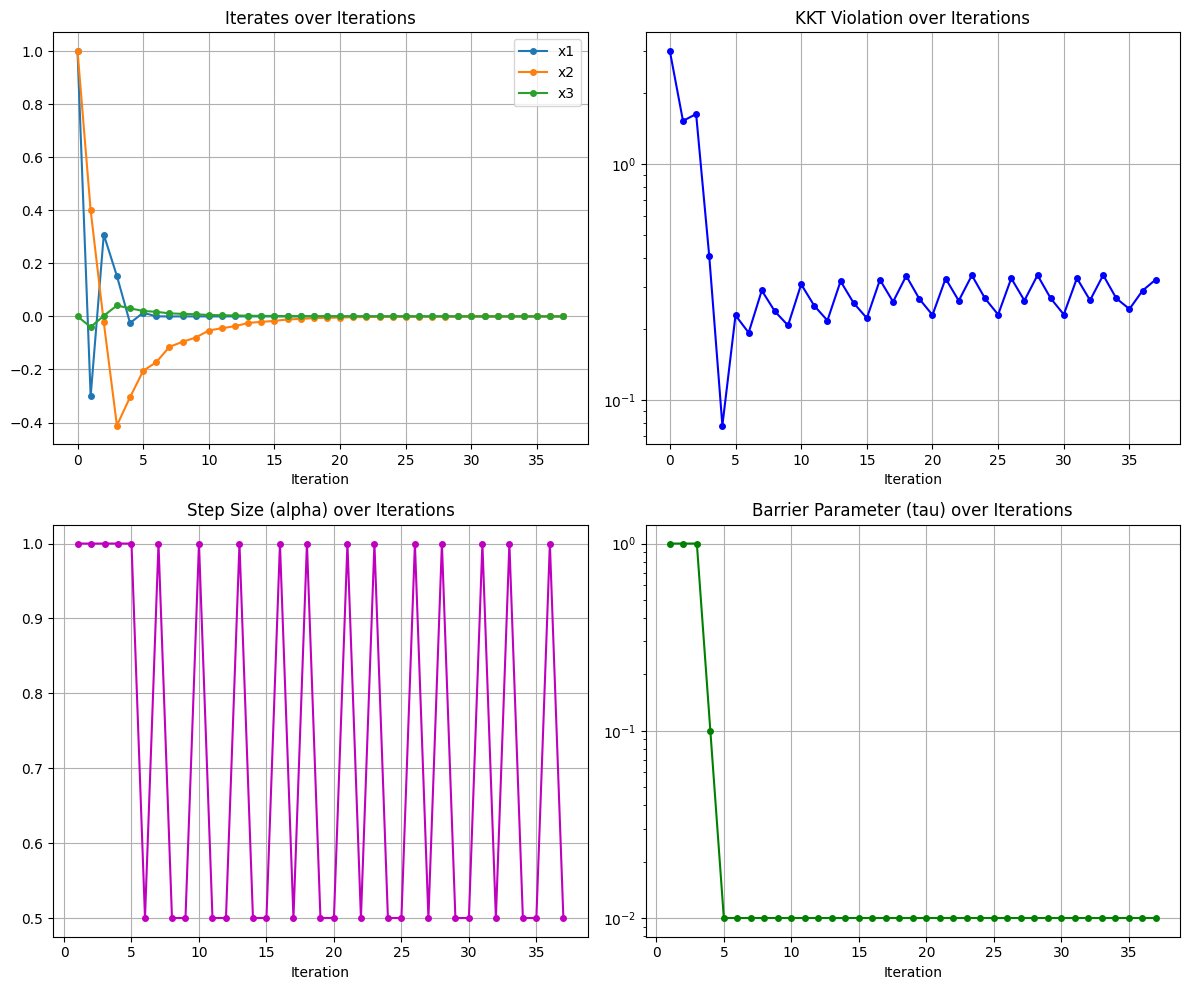

In [42]:
x = ca.SX.sym("x", 3)
f2 = ca.Function("f", [x], [x.T @ x + x[1]])
g2 = ca.Function("g", [x], [ca.vertcat(x[0] ** 2 - 2 * x[1] ** 3 - x[1] - 10 * x[2], x[1] + 10 * x[2])])
h2_none = ca.Function("h", [x], [ca.SX(0, 1)])  # no inequality constraints

compare_newton("Example 2", f2, g2, h2_none, np.array([[1.0], [1.0], [0.0]]), np.array([[0.0], [0.0]]), tol=1e-9)

### Summary: interior point vs Newton

In [43]:
print(f"{'x0':>16} | {'IP solution':>34} | {'IP iter':>7} | {'Newton solution':>34} | {'Newton iter':>11}")
print("-" * 114)
for r in results_eq:
    ip_x = "failed" if r["ip_x"] is None else fmt(r["ip_x"])
    n_x = "failed" if r["newton_x"] is None else fmt(r["newton_x"])
    print(
        f"{fmt(r['x0'], 8):>16} | {ip_x:>34} | {str(r['ip_iter']):>7} | "
        f"{n_x:>34} | {str(r['newton_iter']):>11}"
    )

                    x0 |                          IP solution | IP iter |                      Newton solution | Newton iter
----------------------------------------------------------------------------------------------------------------------------
               [0. 1.] |                    [-0.7071 -0.7071] |      12 |                    [-0.7071 -0.7071] |          12
             [-1. -1.] |                    [-0.7071 -0.7071] |       4 |                    [-0.7071 -0.7071] |           4
             [-1.  1.] |                    [-0.7071 -0.7071] |       7 |                    [-0.7071 -0.7071] |           7
               [1. 1.] |                      [0.7071 0.7071] |       4 |                      [0.7071 0.7071] |           4
   [1.       1.000001] |                    [-0.7071 -0.7071] |      47 |                    [-0.7071 -0.7071] |          47
               [0. 0.] |                               failed |    None |                               failed |        None


**Observations.** Without inequality constraints the IP method behaves like Newton's method: on Example 1 same iterates, same number of iterations, same solutions. All the observations of the Newton notebook still hold:

- $(0, 1)$, $(-1, -1)$, $(-1, 1)$, $(0.5, 1)$: convergence to the minimum $x^* = -\tfrac{1}{\sqrt{2}}(1, 1)$.
- $(1, 1)$: convergence to the **maximum** $\tfrac{1}{\sqrt{2}}(1, 1)$, because the iterates stay on the symmetry axis $x_1 = x_2$; with $1 + 10^{-6}$ the symmetry is broken and the method reaches $x^*$.
- $(0, 0)$: $\nabla g = 0$, LICQ fails and the KKT matrix is singular.
- Example 2: at the solution $x^* = 0$ LICQ fails and $x^*$ is not a KKT point. Both methods drive the multipliers to infinity and stop when the line search fails. Here the iterates coincide only up to round-off: as $\lambda$ grows the KKT matrix becomes ill-conditioned and the round-off errors are amplified (relative difference from $10^{-16}$ to $10^{-5}$ in 27 iterations). From iteration 28 the line search accepts different steps, so the two methods stop at different iterations (37 vs 39).

### Example 3 (SQP notebook)

$$\min_x \; x^\top x + \mathbf{1}^\top x \quad \text{s.t.} \quad x^\top x = 1, \quad 0.5 - x_1^2 - x_2 \le 0$$

Same initial guesses as in the SQP notebook, with $\lambda = 0$ and the default $\mu = 1$. For comparison, each case is also solved with the SQP solver.

In [44]:
x = ca.SX.sym("x", 2)
f = ca.Function("f", [x], [x.T @ x + ca.SX.ones(2).T @ x])
g = ca.Function("g", [x], [x.T @ x - 1])
h = ca.Function("h", [x], [0.5 - x[0] ** 2 - x[1]])

results = []


def compare(x0):
    """Solve with the interior-point method (and plot), then with SQP for comparison"""
    x_ip, l_ip, m_ip, s_ip, post_proc = interior_point(f, g, h, x0, np.array([[0.0]]), tol=1e-8)
    plot_ip(post_proc, f, g, h, x_ip)
    record_result("Example 3", x_ip, l_ip, post_proc, x0, m_ip)
    row = {"x0": x0.flatten(), "ip_x": x_ip.flatten(), "ip_iter": len(post_proc["step"])}

    try:
        x_sqp, _, _, post_proc_sqp = sqp(
            f, g, h, x0, np.array([[0.0]]), np.array([[0.0]]), tol=1e-8, max_iter=400
        )
        row["sqp_x"], row["sqp_iter"] = x_sqp.flatten(), len(post_proc_sqp["step"])
    except RuntimeError as e:
        print("SQP failed:", e)
        row["sqp_x"], row["sqp_iter"] = None, None

    results.append(row)

#### Initial guesses $(0, 1)$ and $(-1, -1)$


      tau |  Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
  1.0e+00 |     1 |     1.750537 |    2.274e-01 |       2.000e+00 |   0.000000 |       [-4.7684e-01, 1.0000e+00] |       [-3.5763e-07]
  1.0e+00 |     2 |     1.343891 |    3.610e-01 |       1.760e+00 |   0.119868 |       [-8.3347e-01, 8.1632e-01] |        [1.9407e-03]
  1.0e+00 |     3 |     0.670617 |    6.746e-01 |       7.798e-01 |   0.500000 |       [-1.2670e+00, 2.6306e-01] |        [9.2284e-02]
  1.0e-01 |     4 |    -0.045088 |    2.245e-01 |       2.245e-01 |   1.000000 |      [-1.0923e+00, -1.7729e-01] |       [-4.4159e-04]
  1.0e-01 |     5 |    -0.199061 |    1.586e-02 |       1.586e-02 |   1.000000 |      [-9.8018e-01, -2.3474e-01] |        [2.4392e-02]
  1.0e-02 |     6 |    -0.267300 |    9.327e-03 |       2.096e-02 |   1.000000 |      [-9.5011e-01, -3.2651e-01] |       [-8.9815e-02]
  1.0e-02 |     7 |    -0.286051 |    6.867e-04 |     

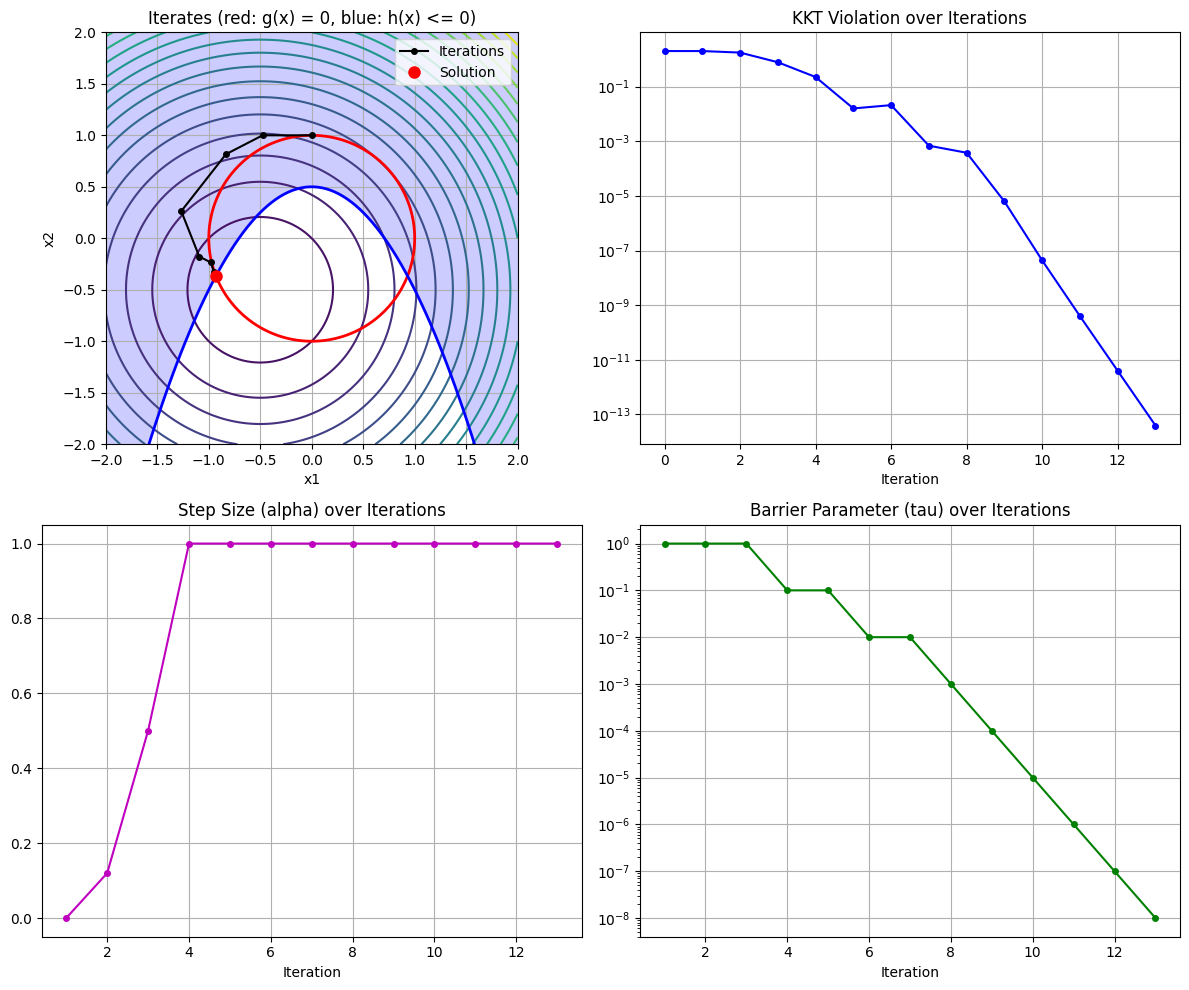

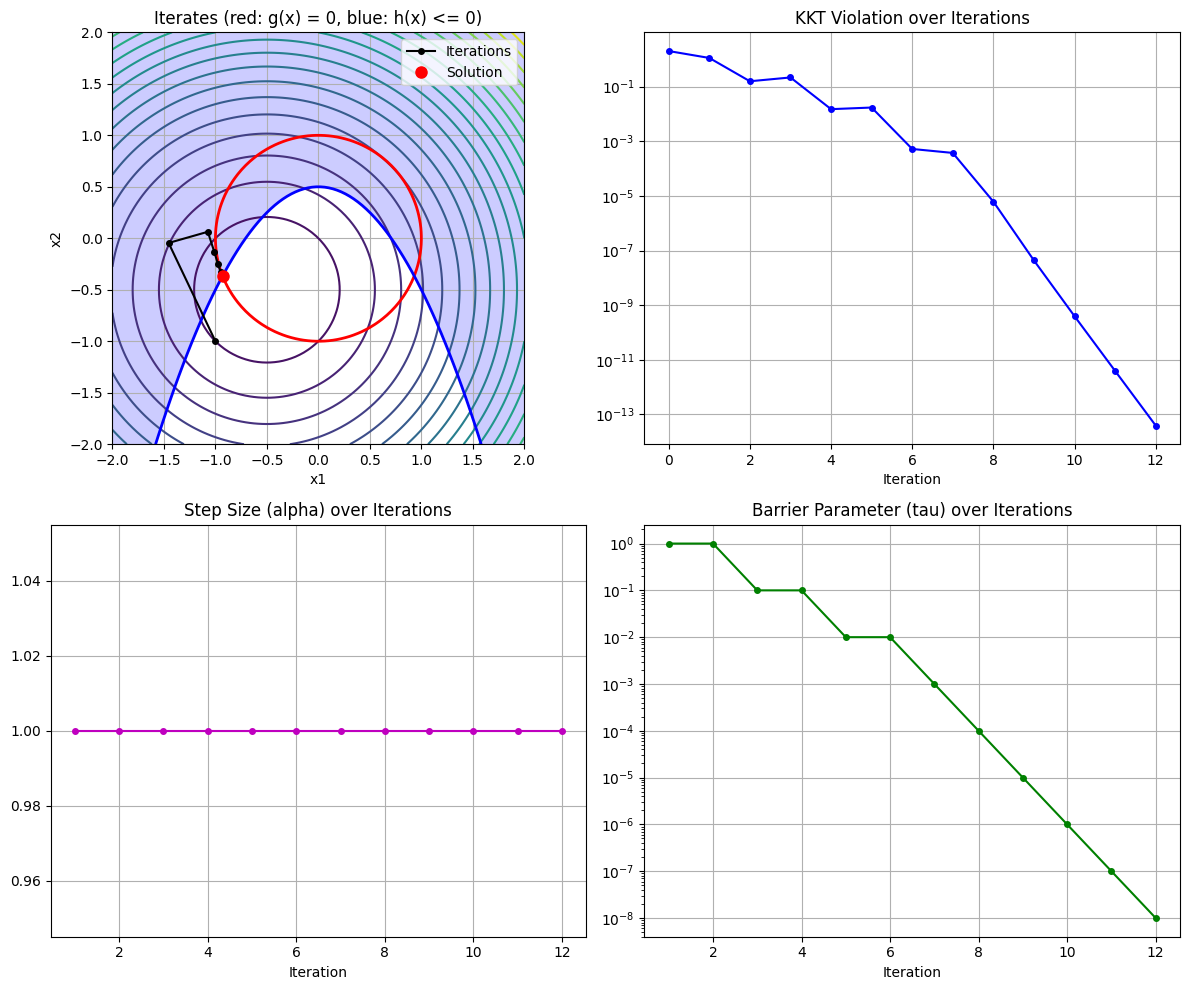

In [45]:
compare(np.array([[0.0], [1.0]]))
compare(np.array([[-1.0], [-1.0]]))

#### Initial guesses $(0.9, 1)$, $(1, -1)$, $(0, -1)$


      tau |  Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
  1.0e+00 |     1 |     2.719923 |    2.185e-01 |       4.801e-01 |   1.000000 |        [9.6440e-01, 5.3704e-01] |       [-5.1852e-01]
  1.0e-01 |     2 |     2.528960 |    2.254e-01 |       4.239e-01 |   0.500000 |        [1.0852e+00, 2.1842e-01] |       [-8.0699e-01]
  1.0e-01 |     3 |     2.305392 |    2.412e-01 |       3.023e-01 |   0.250000 |       [1.1130e+00, -4.8872e-02] |       [-7.7778e-01]
  1.0e-01 |     4 |     1.717467 |    1.649e-01 |       1.649e-01 |   1.000000 |       [9.8770e-01, -4.3517e-01] |       [-7.0121e-01]
  1.0e-01 |     5 |     1.679241 |    1.835e-02 |       1.835e-02 |   1.000000 |       [9.6289e-01, -3.0200e-01] |       [-7.0017e-01]
  1.0e-02 |     6 |     1.579899 |    4.065e-03 |       4.065e-03 |   1.000000 |       [9.3532e-01, -3.5949e-01] |       [-7.3105e-01]
  1.0e-03 |     7 |     1.565615 |    5.378e-05 |     

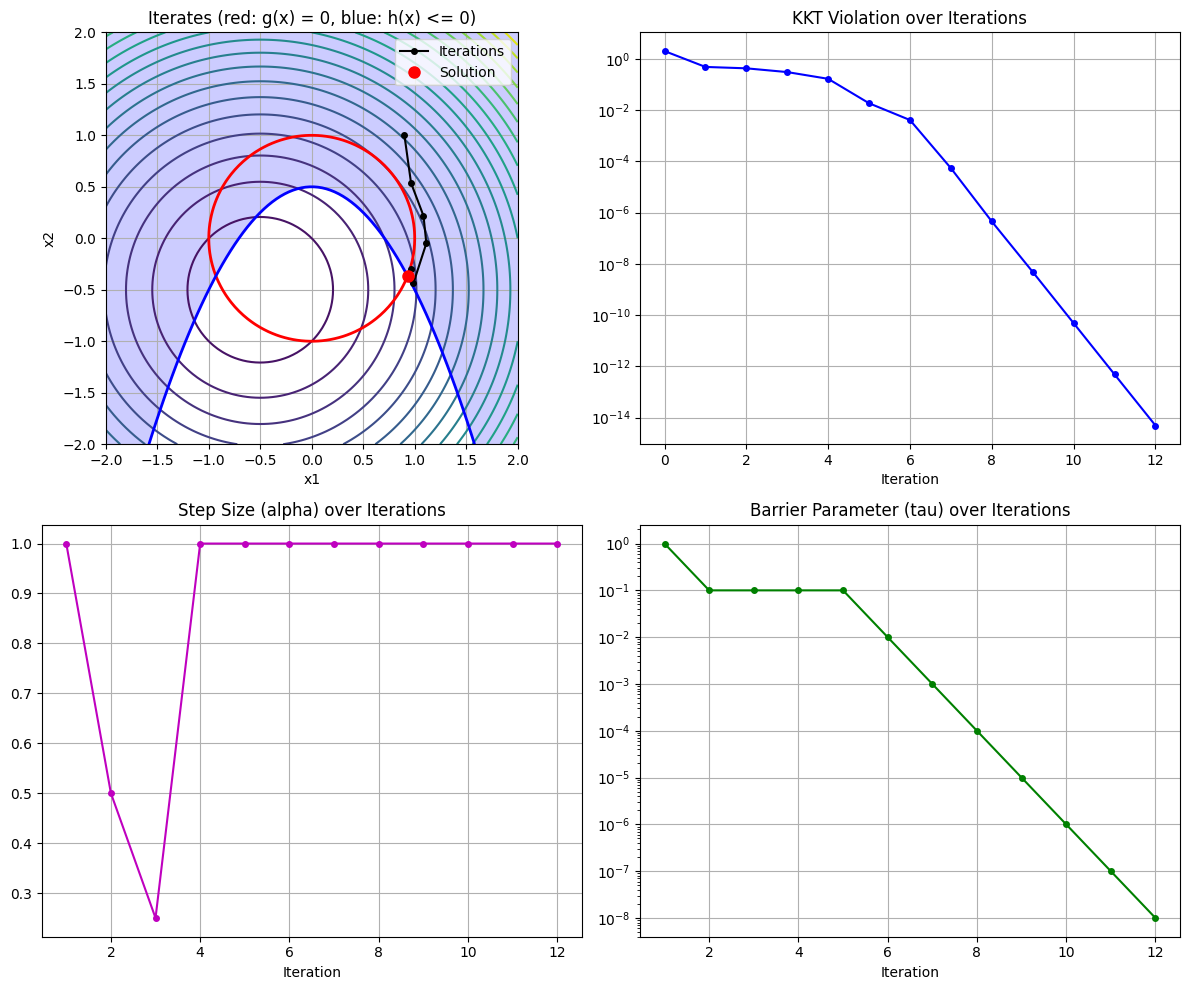

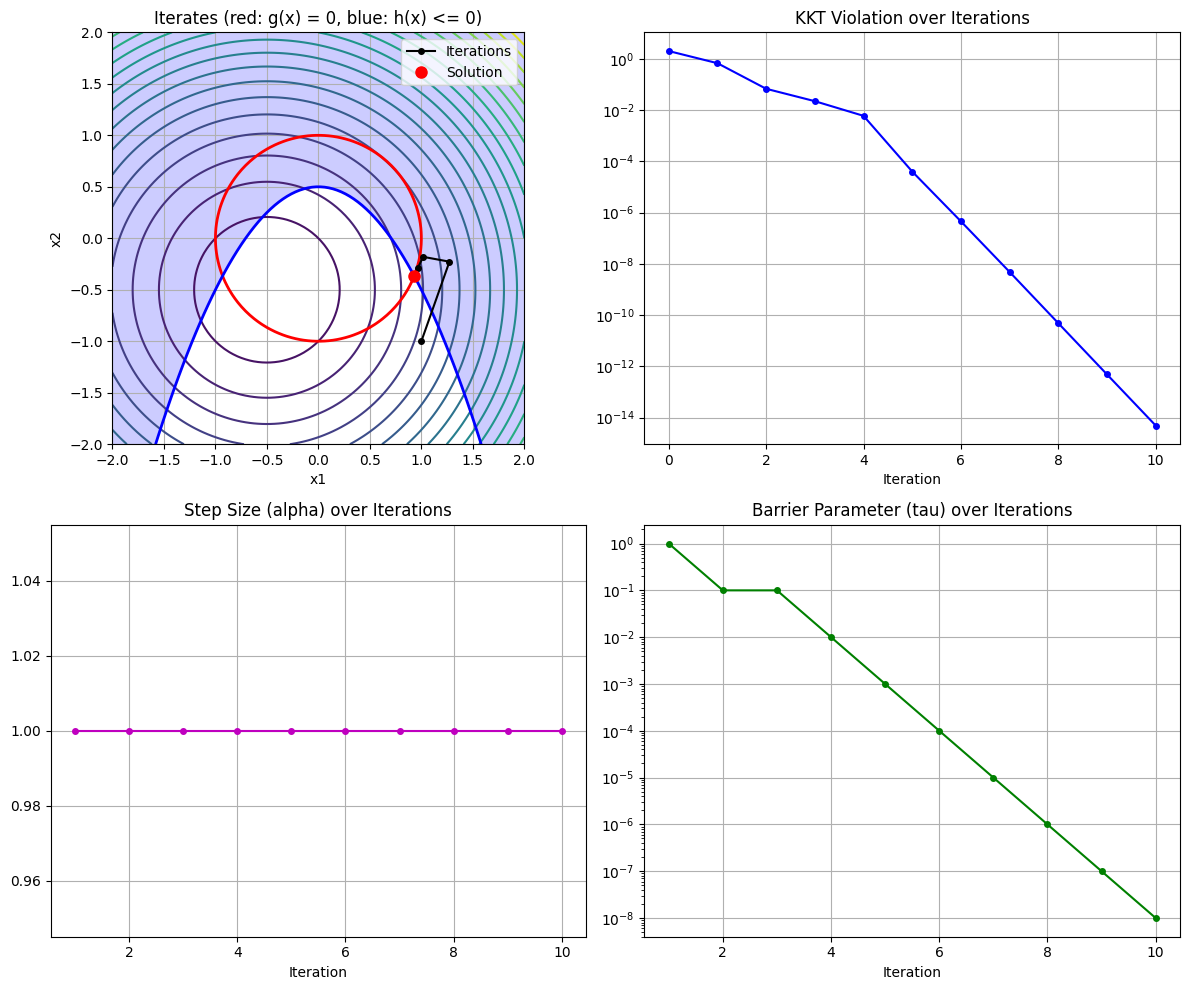

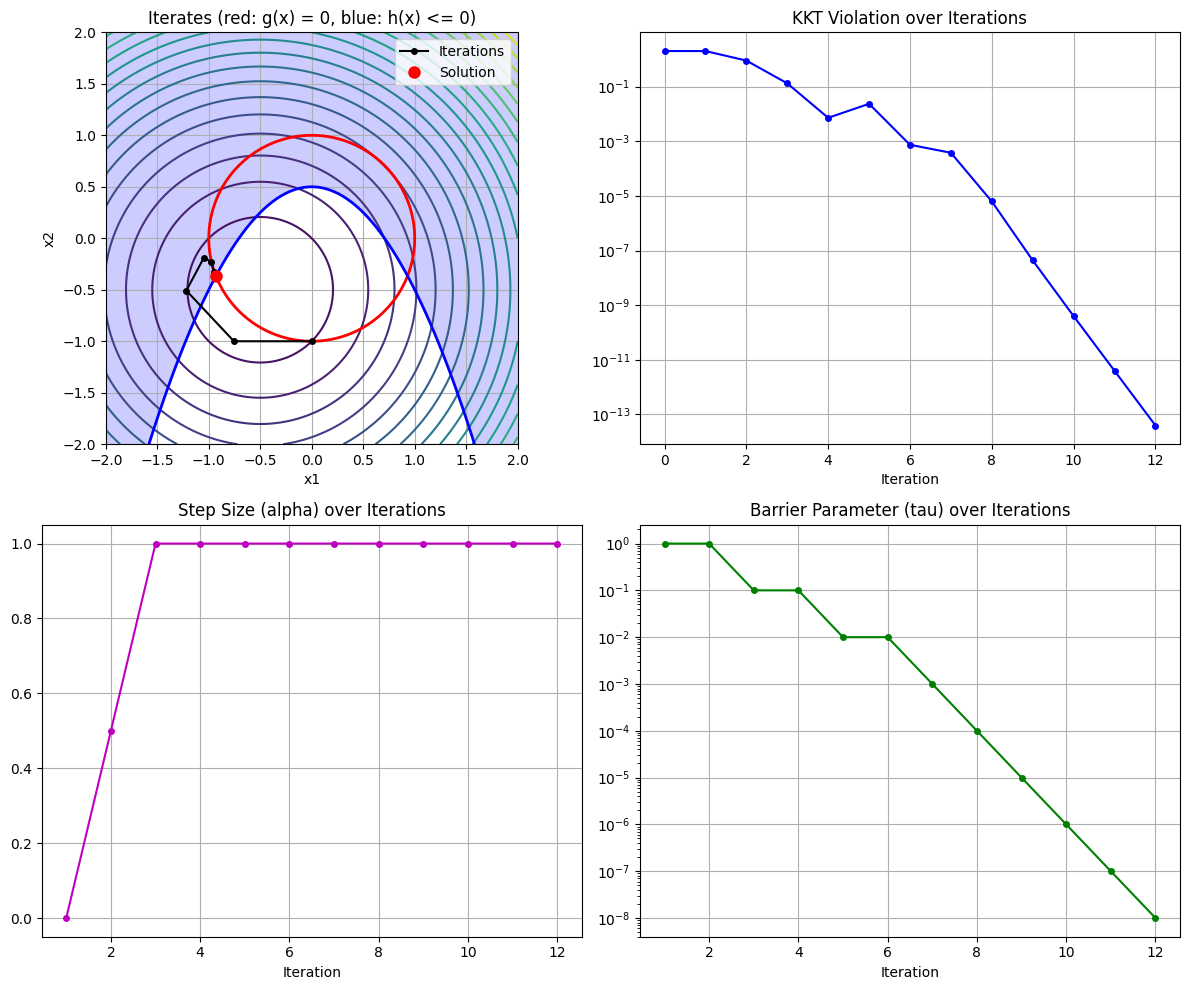

In [46]:
compare(np.array([[0.9], [1.0]]))
compare(np.array([[1.0], [-1.0]]))
compare(np.array([[0.0], [-1.0]]))

### Summary: interior point vs SQP

In [47]:
print(f"{'x0':>10} | {'IP solution':>18} | {'IP iter':>7} | {'SQP solution':>18} | {'SQP iter':>8}")
print("-" * 72)
for r in results:
    sqp_x = "QP infeasible" if r["sqp_x"] is None else fmt(r["sqp_x"])
    sqp_it = "-" if r["sqp_iter"] is None else r["sqp_iter"]
    print(
        f"{fmt(r['x0'], 8):>10} | {fmt(r['ip_x']):>18} | {r['ip_iter']:>7} | "
        f"{sqp_x:>18} | {str(sqp_it):>8}"
    )

              x0 |            IP solution | IP iter |           SQP solution | SQP iter
----------------------------------------------------------------------------------------
         [0. 1.] |      [-0.9306 -0.366 ] |      13 |      [-0.9306 -0.366 ] |        9
       [-1. -1.] |      [-0.9306 -0.366 ] |      12 |      [-0.9306 -0.366 ] |        5
       [0.9 1. ] |      [ 0.9306 -0.366 ] |      12 |      [-0.9306 -0.366 ] |       12
       [ 1. -1.] |      [ 0.9306 -0.366 ] |      10 |      [ 0.9306 -0.366 ] |        5
       [ 0. -1.] |      [-0.9306 -0.366 ] |      12 |          QP infeasible |        -


**Observations.**

- The interior-point method converges from **all** the initial guesses, in 10 to 13 iterations. The KKT violation decreases in a staircase fashion, following the decrease of $\tau$ (one decade per update).
- From $(-1, -1)$ and $(0, -1)$ the initial guess violates the inequality ($h = 0.5$ and $h = 1.5$). This is not a problem for the IP method: with the slack reformulation $h(x) + s = 0$, $s > 0$, the constraint $h(x) \le 0$ only needs to hold at convergence.
- From $(0, -1)$ SQP fails, because the linearized constraints are incompatible and the first QP is infeasible. The IP method has no QP to solve and converges to the global minimum $x^* = (-0.9306, -0.3660)$.
- From $(0.9, 1)$ the IP method converges to the **local** minimum $\bar{x} = (0.9306, -0.3660)$ ($f = 1.565$), while SQP reaches the global one. Both methods are local: on a nonconvex problem they can follow different trajectories and end in different KKT points.
- From $(1, -1)$ both methods converge to the local minimum $\bar{x}$.
- With the default line-search parameters most steps are full steps; the fraction to the boundary and the line search shorten the step only in the first iterations of some cases.
- From $(0, 1)$ and $(0, -1)$ the first step size is $\alpha \approx 10^{-6}$ (printed as 0), yet $x$ moves by about 0.5. At the initial guess $\lambda = 0$, $\mu = 1$ and $\nabla^2_{xx} L = 2I + \mu \nabla^2 h = \operatorname{diag}(0, 2)$. The inequality is not in the active set ($s = \mu$), so $Z = (1, 0)$, the null space of $\nabla g^\top = (0, \pm 2)$, and $Z^\top B Z = 0$: the regularization only lifts it to $\epsilon = 10^{-6}$. The Newton direction is then huge, $\Delta x = (-10^6, 0)$, and the fraction to the boundary and the line search cut the step to $\alpha \approx 10^{-6}$.

### Initial guesses on the symmetry axis $x_1 = x_2$

In Example 1, starting on the diagonal Newton's method stays on it and converges to the maximum. What happens with the inequality constraint of Example 3?

In [48]:
rows = []
for c in [0.5, 1.0, 2.0]:
    x0 = np.array([[c], [c]])
    with contextlib.redirect_stdout(io.StringIO()):  # hide the iterations of the solvers
        x_sqp, _, _, _ = sqp(f, g, h, x0, np.array([[0.0]]), np.array([[0.0]]), tol=1e-8)
        x_ip, _, _, _, _ = interior_point(f, g, h, x0, np.array([[0.0]]), tol=1e-8)
    rows.append((x0.flatten(), x_sqp.flatten(), x_ip.flatten()))

print(f"{'x0':>12} | {'SQP solution':>22} | {'IP solution':>22}")
print("-" * 62)
for x0, x_sqp, x_ip in rows:
    print(f"{str(x0):>12} | {str(np.round(x_sqp, 4)):>22} | {str(np.round(x_ip, 4)):>22}")

          x0 |           SQP solution |            IP solution
--------------------------------------------------------------
   [0.5 0.5] |        [0.7071 0.7071] |      [ 0.9306 -0.366 ]
     [1. 1.] |        [0.7071 0.7071] |      [ 0.9306 -0.366 ]
     [2. 2.] |        [0.7071 0.7071] |      [ 0.9306 -0.366 ]


**Observations.**

- **SQP** converges to the **maximum** $\tfrac{1}{\sqrt{2}}(1, 1)$, a KKT point with the inequality inactive ($\mu = 0$) that does not satisfy SOSC. It starts with $\mu = 0$ and the inequality is inactive, so the QP is symmetric with respect to the diagonal and the iterates never leave it, as in Example 1.
- **IP** never stays on the diagonal. It starts with $\mu = 1$: the term $\mu \nabla h = \mu(-2x_1, -1)$ in $\nabla_x L$ and the curvature $\mu \nabla^2 h = \operatorname{diag}(-2\mu, 0)$ in $B$ are not symmetric, so the symmetry is broken at the first step. From these points it converges to the local minimum $\bar{x} = (0.9306, -0.3660)$.

On a nonconvex problem both methods only find KKT points, which can be maxima or local minima.

### Effect of the initialization of the interior-point method

From $(0.9, 1)$ the IP method converges to the local minimum $\bar{x}$, while SQP reaches the global one. The point $(0.9, 1)$ is close to the maximum of $f$ on the circle ($48^\circ$ vs $45^\circ$), which separates the two minima: small differences in the first step decide where the method goes. Changing the initial $\mu$ or $\tau$ changes the first step:

In [49]:
rows = []
for mu0, tau0 in [(1.0, 1.0), (0.1, 1.0), (1.0, 0.1)]:
    with contextlib.redirect_stdout(io.StringIO()):  # hide the iterations of the solver
        x_ip, _, _, _, post_proc = interior_point(
            f, g, h, np.array([[0.9], [1.0]]), np.array([[0.0]]), m_g=mu0, tau=tau0, tol=1e-8
        )
    rows.append((mu0, tau0, post_proc["x"][1], x_ip.flatten()))

print(f"{'mu0':>6} | {'tau0':>6} | {'first iterate':>18} | {'solution':>20}")
print("-" * 60)
for mu0, tau0, x1, x_ip in rows:
    print(f"{mu0:>6} | {tau0:>6} | {str(np.round(x1, 3)):>18} | {str(np.round(x_ip, 4)):>20}")

   mu0 |   tau0 |      first iterate |             solution
------------------------------------------------------------
   1.0 |    1.0 |      [0.964 0.537] |    [ 0.9306 -0.366 ]
   0.1 |    1.0 |      [0.708 0.768] |    [-0.9306 -0.366 ]
   1.0 |    0.1 |      [0.381 1.182] |    [-0.9306 -0.366 ]


**Observations.** With the default $\mu_0 = \tau_0 = 1$ the first step goes to the right side of the circle and the method ends in $\bar{x}$; with a smaller $\mu_0$ or $\tau_0$ the first step resembles the SQP one and the method reaches the global minimum. A local method gives no guarantee of finding the global minimum: a good initial guess (or global optimization) is needed.

## Summary

In [ ]:
print(
    f"{'Example':>9} | {'x0':>16} | {'solution':>34} | {'lambda':>22} | {'mu':>9} | {'iter':>4} | {'KKT':>9}"
)
print("-" * 122)
for r in optimization_results:
    print(
        f"{r['example']:>9} | {fmt(r['initial_guess'], 8):>16} | {fmt(r['solution']):>34} | "
        f"{fmt(r['equality_multiplier']):>22} | {fmt(r['inequality_multiplier']):>9} | "
        f"{r['iterations']:>4} | {r['kkt_violation']:>9.2e}"
    )